# DAL applicant simulation

I wanted to know how I might compare with the people likely to apply to DAL Academy. I could not
use real applicants, so I built a synthetic pool, simulated how it would answer the 45 question DAL
self-assessment, and compared the result with my own answers.

**Update after the video**

I made a few changes after recording the video, so some numbers here differ from the ones I show
in it.

* KFUPM Data Science and Engineering was already scored in the workbook but had no applicants in
  the pool. I added 20 to the Applicants sheet, with GPA, age and experience resampled from existing
  applicants. The programme is recent and I could not verify its first graduating year, so these 20
  are 2025 and 2026 graduates only. The pool is now 210 applicants across 10 programmes. Before
  this it was 190 across 9.
* I tidied the labels and the text. The model and its assumptions are the same.

Section 7 compares my results before and after this change.

**Method**

1. **Curriculum scoring.** I scored each degree programme against the 45 competencies using its
   official study plan. Every score has a confidence level. This lives in the workbook
   `DAL data.xlsx`.
2. **Unknown evidence.** About a third of the cells have no evidence. A score of 1 there means
   "not verified", not "not taught". So everything is run twice: `low` (unknown = 1) and `typical`
   (unknown = the average of the programmes that do have evidence for that question, which leans
   generous). I treat the two as bounds.
3. **Synthetic applicants.** 210 fictional applicants across 10 programmes, each with a GPA, a
   graduation year and years of experience.
4. **Monte Carlo simulation.** 10,000 iterations. Each one draws a curriculum error per programme
   (shared by its applicants), an ability and self-learning term per person, and how much people
   inflate or compress their self ratings. Latent skill is not clipped. Only the final answer is
   clipped to the 1 to 10 scale.
5. **Testing it on myself.** I predict my own answers with the same model and compare them with
   what I actually answered.
6. **Rank as a range.** The pool is model output, not real applicants, so I report my rank as a
   range between an optimistic and a pessimistic bound and not as one number.


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Settings
FILE_PATH = "DAL data.xlsx"
N_ITER = 10000
SEED = 42

# (in case) The 20 KFUPM applicants are now rows in the workbook's Applicants sheet, so this
# does nothing with the current workbook. If a programme listed here has no applicants in the
# workbook, this many are generated, resampled from recent graduates only.
EXTRA_APPLICANTS = {"P15": 20}   # KFUPM Data Science and Engineering
EXTRA_MIN_GRAD_YEAR = 2025       # earliest graduation year for generated applicants

# My profile
MY_GPA_100 = 94.4            # 4.72 / 5 expressed on the workbook's 0-100 scale
MY_EXPERIENCE_YEARS = 0
MY_GRADUATION_YEAR = 2026
MY_DEGREE_FAMILIES = ["IS"]

# My required courses
MY_COURSES = {
    "Programming": ["Programming for Analytics"],
    "Databases": ["Database Management"],
    "Statistics": ["Business Statistics", "Math & Stats for Analytics"],
    "Machine learning": ["Predictive Analytics"],
}

# My actual answers to the DAL self-assessment
ACTUAL_ANSWERS = {
    "P01": 7, "P02": 7, "P03": 6, "P04": 6, "P05": 7, "P06": 8, "P07": 7,
    "D01": 8, "D02": 8, "D03": 7, "D04": 8, "D05": 8, "D06": 9, "D07": 8,
    "M01": 9, "M02": 8, "M03": 8, "M04": 9, "M05": 7, "M06": 8,
    "B01": 8, "B02": 8, "B03": 9, "B04": 10, "B05": 10, "B06": 8, "B07": 10, "B08": 9,
    "ML01": 8, "ML02": 7, "ML03": 7, "ML04": 6, "ML05": 7, "ML06": 8, "ML07": 7,
    "AI01": 7, "AI02": 7, "AI03": 7, "AI04": 7, "AI05": 6, "AI06": 6,
    "R01": 6, "R02": 5, "R03": 6, "R04": 7,
}

UNCERTAINTY = {"high": 0.4, "medium": 0.8, "low": 1.3, "very low": 2.0}
MODERN_SKILLS = ["AI03", "AI04", "AI05", "AI06"]

if not os.path.exists(FILE_PATH):
    from google.colab import files
    files.upload()

In [5]:
workbook = pd.read_excel(FILE_PATH, sheet_name=None)

applicants = workbook["Applicants"].copy()
curriculum = workbook["Curriculum Scores"].copy()
evidence = workbook["Score Evidence"].copy()
questions = workbook["Question Key"].copy()
rules = workbook["Inference Rules"].copy()
priors = workbook["Degree Priors"].copy()

# Add synthetic applicants for scored programmes that have none in the workbook (see settings).
# They are resampled from existing applicants who graduated in EXTRA_MIN_GRAD_YEAR or later.
extra = []
for k, (pid, n) in enumerate(EXTRA_APPLICANTS.items()):
    if n == 0 or (applicants["Program ID"] == pid).any():
        continue
    prog = curriculum.loc[curriculum["Program ID"] == pid].iloc[0]
    donors = applicants[applicants["Graduation year"] >= EXTRA_MIN_GRAD_YEAR]
    rows = donors.sample(n, replace=True, random_state=SEED + k).copy()
    rows["Program ID"] = pid
    rows["University"] = prog["University"]
    rows["Major"] = prog["Major"]
    # region, type and course-family columns come from the programme, not from the resampled rows
    meta = workbook["Curriculum Matrix"].set_index("Program ID").loc[pid]
    for col in meta.index.intersection(rows.columns):
        rows[col] = meta[col]
    rows["Applicant ID"] = [f"SYN{900 + 50 * k + i:03d}" for i in range(1, n + 1)]
    extra.append(rows)
if extra:
    applicants = pd.concat([applicants] + extra, ignore_index=True)

skill_cols = questions["Question ID"].tolist()
domains = questions["Domain"].unique()

population = applicants.merge(
    curriculum[["Program ID"] + skill_cols],
    on="Program ID", how="left", validate="many_to_one",
)

assert len(skill_cols) == 45
N_POP = len(population)
assert population[skill_cols].notna().all().all()
assert set(ACTUAL_ANSWERS) == set(skill_cols)

print("Applicants:", len(population), "| competencies:", len(skill_cols),
      "| programmes with applicants:", population["Program ID"].nunique())

Applicants: 210 | competencies: 45 | programmes with applicants: 10


## 1. How much of the curriculum score is real evidence?

A cell is **unknown** when it is unverified and sits at the default score of 1 (no course rule and
no degree prior applied). The check below shows how strongly a programme's average score follows
simply how many of its 45 cells have any evidence.

In [7]:
score_m = evidence.pivot(index="Program ID", columns="Question ID", values="Baseline score")[skill_cols]
status_m = evidence.pivot(index="Program ID", columns="Question ID", values="Status")[skill_cols]
conf_m = evidence.pivot(index="Program ID", columns="Question ID", values="Confidence")[skill_cols]

unknown_m = (status_m == "Unverified") & (score_m == 1)

audit = curriculum[["Program ID", "University", "Major"]].set_index("Program ID")
audit["Cells with evidence or prior"] = (~unknown_m).sum(axis=1)
audit["Unknown cells"] = unknown_m.sum(axis=1)
audit["Mean curriculum score"] = score_m.mean(axis=1).round(2)
display(audit.sort_values("Mean curriculum score", ascending=False))

rho, _ = stats.spearmanr(audit["Cells with evidence or prior"], audit["Mean curriculum score"])
print(f"Share of all cells that are unknown: {unknown_m.values.mean():.0%}")
print(f"Spearman correlation, evidence coverage vs mean score: {rho:.2f}")

,University,Major,Cells with evidence or prior,Unknown cells,Mean curriculum score
Program ID,,,,,
P15,KFUPM,Data Science and Engineering,44,1,3.71
P07,Imam Abdulrahman Bin Faisal University,Computer Science,35,10,3.40
P09,King Abdulaziz University,Computer Science,34,11,3.29
P05,King Saud University,Information Systems,29,16,2.96
P11,Qassim University,Computer Science,35,10,2.89
P01,Prince Sultan University,Information Systems,28,17,2.78
P06,Prince Mohammad Bin Fahd University,Management Information Systems,27,18,2.73
P02,Prince Sultan University,Software Engineering,25,20,2.60
P03,Prince Sultan University,Industrial and Systems Engineering,23,22,2.40


Share of all cells that are unknown: 33%
Spearman correlation, evidence coverage vs mean score: 0.95


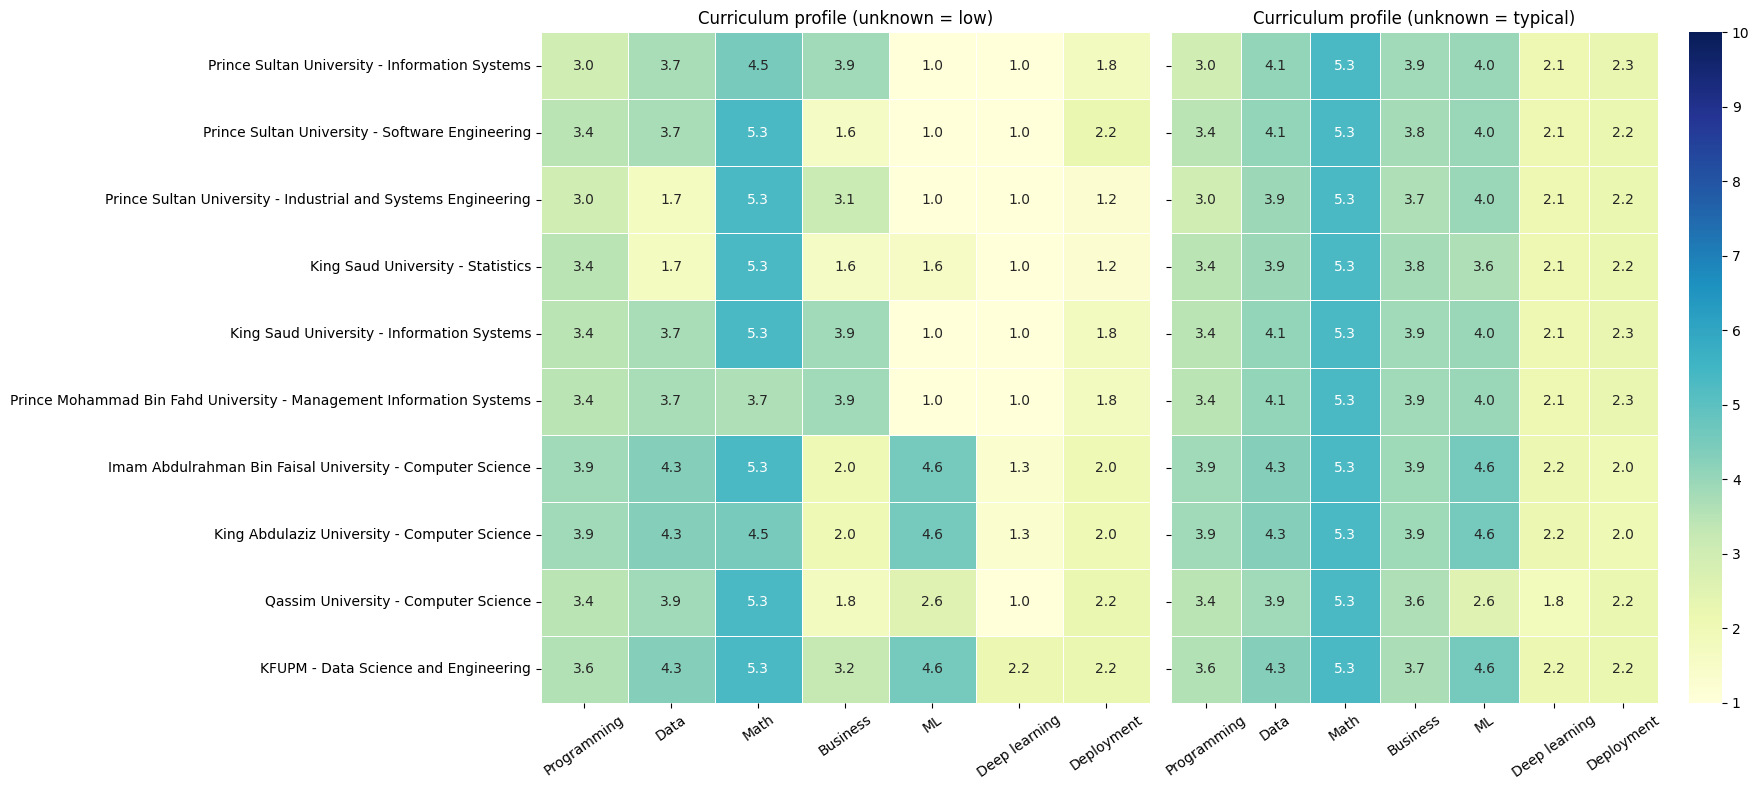

In [8]:
# Two scenarios for unknown cells
#   low     : unknown = 1 (as scored in the workbook)
#   typical : unknown = mean score of programmes that DO have evidence or a prior for that
#             question (stays 1 only if no programme has any). This leans generous, because
#             programmes that list a topic are the ones most likely to teach it well.
# The two scenarios are bounds; the truth for any one programme lies between them.
question_ref = score_m.where(~unknown_m).mean(axis=0).fillna(1.0)

score_by_mode = {
    "low": score_m.astype(float),
    "typical": score_m.astype(float).where(~unknown_m, question_ref, axis=1),
}

unc_m = conf_m.apply(lambda c: c.astype(str).str.strip().str.lower().map(UNCERTAINTY)).fillna(2.0)

domain_matrix = np.column_stack([
    np.isin(skill_cols, questions.loc[questions["Domain"] == d, "Question ID"])
    for d in domains
]).astype(float)
domain_matrix /= domain_matrix.sum(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)
labels = (curriculum["University"] + " - " + curriculum["Major"]).values
for ax, mode in zip(axes, ["low", "typical"]):
    dom = pd.DataFrame(score_by_mode[mode].loc[curriculum["Program ID"]].to_numpy() @ domain_matrix,
                       index=labels, columns=domains)
    sns.heatmap(dom, annot=True, fmt=".1f", cmap="YlGnBu", vmin=1, vmax=10,
                linewidths=0.5, ax=ax, cbar=(mode == "typical"))
    ax.set_title(f"Curriculum profile (unknown = {mode})")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 2. My curriculum baseline

Course rules first, degree prior otherwise (the workbook's stated approach). Anything left over is
unknown and handled by the same two scenarios as the population.

In [9]:
def my_curriculum(mode):
    rows = []
    for q in skill_cols:
        matched = rules[(rules["Question ID"] == q) & rules["Course family"].isin(list(MY_COURSES))]
        prior = priors[priors["Degree family"].isin(MY_DEGREE_FAMILIES) & (priors["Question ID"] == q)]
        if not matched.empty:
            score, unc = matched["Required score"].max(), UNCERTAINTY["medium"]
            src = "; ".join(sorted({c for fam in matched["Course family"] for c in MY_COURSES[fam]}))
        elif not prior.empty:
            score, unc, src = prior["Prior score"].max(), UNCERTAINTY["low"], "Degree prior"
        else:
            score = 1.0 if mode == "low" else question_ref[q]
            unc, src = UNCERTAINTY["very low"], "Unknown"
        rows.append((q, float(score), unc, src))
    return pd.DataFrame(rows, columns=["Question ID", "Curriculum score", "Uncertainty", "Evidence"])

my_cur = {m: my_curriculum(m) for m in ["low", "typical"]}

view = questions.merge(my_cur["low"][["Question ID", "Curriculum score", "Evidence"]], on="Question ID")
view = view.rename(columns={"Curriculum score": "Score (unknown = low)"})
view["Score (unknown = typical)"] = my_cur["typical"]["Curriculum score"].round(2).values
display(view)

,Question ID,Domain,Question,Score (unknown = low),Evidence,Score (unknown = typical)
0,P01,Programming,Python independently,2.0,Programming for Analytics,2.0
1,P02,Programming,Clean modular code,4.0,Programming for Analytics,4.0
2,P03,Programming,Object-oriented programming,3.0,Programming for Analytics,3.0
3,P04,Programming,Debugging and stack traces,4.0,Programming for Analytics,4.0
4,P05,Programming,Testing and error handling,3.0,Programming for Analytics,3.0
5,P06,Programming,Command line and environments,3.0,Programming for Analytics,3.0
6,P07,Programming,"Git, REST APIs and collaboration",2.0,Programming for Analytics,2.0
7,D01,Data,Data structures and efficiency,3.0,Programming for Analytics,3.0
8,D02,Data,SQL filtering and aggregation,6.0,Database Management,6.0
9,D03,Data,"SQL joins, CTEs and windows",4.0,Database Management,4.0


## 3. Simulation

Every iteration draws a curriculum error per programme (shared), a person-level ability and
self-learning term, and the behavioural assumptions (inflation 0 to 1.5, midpoint compression
0 to 0.4). I am simulated inside the same loop, under the same draws, in three ways:

* **curriculum-only**: predicted from my curriculum alone, as a reference
* **like-for-like**: with the same person-level terms as everybody else
* **actual**: my real answers


In [10]:
experience = pd.to_numeric(population["Experience years"], errors="coerce").fillna(0).clip(lower=0).to_numpy()
gpa = pd.to_numeric(population["Simulated GPA /100"], errors="coerce").fillna(75).to_numpy()
graduation = pd.to_numeric(population["Graduation year"], errors="coerce").fillna(2026).to_numpy()

modern = np.isin(skill_cols, MODERN_SKILLS).astype(float)

def person_effects(gpa, experience, graduation):
    gpa_eff = (np.asarray(gpa, float) - 75) / 25
    exp_eff = 0.45 * np.log1p(np.asarray(experience, float))
    recency = -0.12 * np.maximum(2023 - np.asarray(graduation, float), 0)
    return gpa_eff, exp_eff, recency

pop_gpa, pop_exp, pop_rec = person_effects(gpa, experience, graduation)
my_gpa, my_exp, my_rec = person_effects(MY_GPA_100, MY_EXPERIENCE_YEARS, MY_GRADUATION_YEAR)

program_ids, program_index = np.unique(population["Program ID"], return_inverse=True)
actual_vec = np.array([ACTUAL_ANSWERS[q] for q in skill_cols], dtype=float)
actual_domains = actual_vec @ domain_matrix


def report(latent, inflation, calibration, rng, n_people):
    """Questionnaire answer from latent skill. Only the answer is clipped to the 1-10 scale."""
    bias = rng.normal(inflation, 0.6, (n_people, 1))
    noise = rng.normal(0, 0.6, latent.shape)
    return np.clip(np.rint(latent + bias + calibration * (5.5 - latent) + noise), 1, 10)


def simulate(mode, n_iter=N_ITER, seed=SEED):
    rng = np.random.default_rng(seed)
    base_prog = score_by_mode[mode].loc[program_ids].to_numpy()
    unc_prog = unc_m.loc[program_ids].to_numpy()
    me_base = my_cur[mode]["Curriculum score"].to_numpy()
    me_unc = my_cur[mode]["Uncertainty"].to_numpy()
    n, k = len(population), len(skill_cols)

    out = dict(
        scores=np.zeros((n_iter, n)), ranks=np.zeros((n_iter, n)), bias=np.zeros(n_iter),
        me_cur=np.zeros((n_iter, k)), me_full=np.zeros((n_iter, k)),
        score_actual=np.zeros(n_iter),
        rank_cur=np.zeros(n_iter), rank_full=np.zeros(n_iter), rank_actual=np.zeros(n_iter),
    )

    def rank_of(x, pool):
        return 1 + np.sum(pool > x) + 0.5 * np.sum(pool == x)

    for i in range(n_iter):
        # shared curriculum error: one draw per programme
        prog_latent = base_prog + rng.normal(0, 1, base_prog.shape) * unc_prog
        latent = (
            prog_latent[program_index]
            + rng.normal(0, 0.8, (n, 1))          # ability
            + rng.gamma(1.5, 0.5, (n, 1))         # self-learning
            + pop_gpa[:, None] + pop_exp[:, None]
            + pop_rec[:, None] * modern[None, :]
        )

        inflation = rng.uniform(0, 1.5)
        calibration = rng.uniform(0, 0.4)
        weights = rng.dirichlet(np.ones(len(domains)) * 3)

        answers = report(latent, inflation, calibration, rng, n)
        pool = answers @ domain_matrix @ weights

        out["scores"][i] = pool
        out["ranks"][i] = stats.rankdata(-pool, method="average")
        out["bias"][i] = (answers - np.clip(latent, 1, 10)).mean()

        # me
        me_latent_cur = (me_base + rng.normal(0, 1, k) * me_unc)[None, :]
        me_latent_full = (
            me_latent_cur + rng.normal(0, 0.8) + rng.gamma(1.5, 0.5)
            + my_gpa + my_exp + my_rec * modern[None, :]
        )
        a_cur = report(me_latent_cur, inflation, calibration, rng, 1)[0]
        a_full = report(me_latent_full, inflation, calibration, rng, 1)[0]
        out["me_cur"][i], out["me_full"][i] = a_cur, a_full

        s_actual = actual_domains @ weights
        out["score_actual"][i] = s_actual
        out["rank_cur"][i] = rank_of(a_cur @ domain_matrix @ weights, pool)
        out["rank_full"][i] = rank_of(a_full @ domain_matrix @ weights, pool)
        out["rank_actual"][i] = rank_of(s_actual, pool)
    return out


sim = {mode: simulate(mode) for mode in ["low", "typical"]}
print("Done:", N_ITER, "iterations x 2 scenarios")
for mode, s in sim.items():
    print(f"  {mode:8s} mean pool score {s['scores'].mean():.2f} | "
          f"mean reporting bias {s['bias'].mean():.2f} (an input assumption, not a finding)")

Done: 10000 iterations x 2 scenarios
  low      mean pool score 5.29 | mean reporting bias 0.90 (an input assumption, not a finding)
  typical  mean pool score 5.81 | mean reporting bias 0.82 (an input assumption, not a finding)


## 4. Population results

Ability and self-learning are redrawn every iteration, so an applicant's position here reflects only
their programme, GPA and experience. The width of the intervals is the main message.

,Applicant ID,University,Major,Graduation year,Experience years,Mean score,Mean rank,Rank 5th pct,Rank 95th pct,Top 10% freq,Top 20% freq,Top 30% freq
159,SYN204,King Abdulaziz University,Computer Science,2019,7,6.83,50.50,2.0,150.00,36.42,55.64,68.78
35,SYN036,Prince Sultan University,Information Systems,2019,6,6.62,60.33,3.0,163.00,28.94,47.32,60.71
2,SYN003,Prince Sultan University,Software Engineering,2019,7,6.57,62.88,4.0,165.00,26.87,45.10,58.84
116,SYN129,Imam Abdulrahman Bin Faisal University,Computer Science,2019,7,6.48,67.98,4.0,170.05,24.25,40.93,54.33
71,SYN072,Prince Sultan University,Industrial and Systems Engineering,2017,5,6.46,68.62,4.0,172.00,23.06,40.29,53.86
131,SYN150,Imam Abdulrahman Bin Faisal University,Computer Science,2017,5,6.35,75.02,5.0,178.00,20.01,36.11,49.35
167,SYN218,King Abdulaziz University,Computer Science,2021,4,6.32,76.29,5.0,178.00,19.65,34.84,48.32
87,SYN088,Prince Sultan University,Information Systems,2018,5,6.31,76.85,6.0,179.00,18.96,34.46,47.83
186,SYN261,Qassim University,Computer Science,2018,8,6.30,77.07,5.0,180.05,18.64,34.72,47.73
150,SYN192,King Abdulaziz University,Computer Science,2025,1,6.30,77.54,5.0,180.00,19.14,34.06,47.56


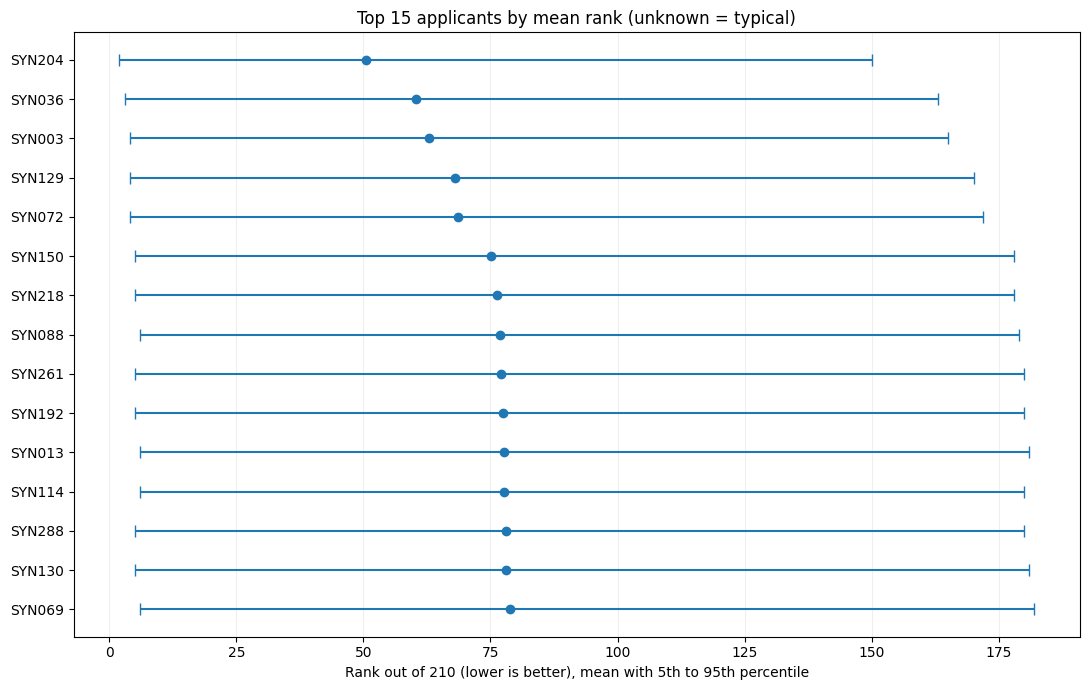

In [11]:
def applicant_table(s):
    r = population[["Applicant ID", "University", "Major", "Graduation year", "Experience years"]].copy()
    r["Mean score"] = s["scores"].mean(axis=0)
    r["Mean rank"] = s["ranks"].mean(axis=0)
    r["Rank 5th pct"] = np.percentile(s["ranks"], 5, axis=0)
    r["Rank 95th pct"] = np.percentile(s["ranks"], 95, axis=0)
    for pct in (10, 20, 30):
        cut = N_POP * pct / 100
        r[f"Top {pct}% freq"] = (s["ranks"] <= cut).mean(axis=0) * 100
    return r.sort_values("Mean rank")

results = {m: applicant_table(s) for m, s in sim.items()}
display(results["typical"].head(15).round(2))

top = results["typical"].head(15).sort_values("Mean rank", ascending=False)
plt.figure(figsize=(11, 7))
plt.errorbar(top["Mean rank"], top["Applicant ID"],
             xerr=[top["Mean rank"] - top["Rank 5th pct"], top["Rank 95th pct"] - top["Mean rank"]],
             fmt="o", capsize=4)
plt.xlabel(f"Rank out of {N_POP} (lower is better), mean with 5th to 95th percentile")
plt.title("Top 15 applicants by mean rank (unknown = typical)")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Applicants  \
University                             Major                                            
Prince Sultan University               Information Systems                         23   
Imam Abdulrahman Bin Faisal University Computer Science                            28   
King Abdulaziz University              Computer Science                            32   
King Saud University                   Statistics                                  21   
                                       Information Systems                         11   
Prince Sultan University               Software Engineering                        23   
KFUPM                                  Data Science and Engineering                20   
Prince Mohammad Bin Fahd University    Management Information Systems              19   
Prince Sultan University               Industrial and Systems Engineering          15   
Qassim University                      Computer Science                            18   

                                                                           Mean_rank (low)  \
University                             Major                                                 
Prince Sultan University               Information Systems                           105.4   
Imam Abdulrahman Bin Faisal University Computer Science                               87.4   
King Abdulaziz University              Computer Science                               94.7   
King Saud University                   Statistics                                    125.2   
                                       Information Systems                           103.9   
Prince Sultan University               Software Engineering                          115.1   
KFUPM                                  Data Science and Engineering                   82.0   
Prince Mohammad Bin Fahd University    Management Information Systems                122.3   
Prince Sultan University               Industrial and Systems Engineering            129.7   
Qassim University                      Computer Science                              107.0   

                                                                           Top_20 (low)  \
University                             Major                                              
Prince Sultan University               Information Systems                         18.9   
Imam Abdulrahman Bin Faisal University Computer Science                            28.4   
King Abdulaziz University              Computer Science                            24.4   
King Saud University                   Statistics                                  11.7   
                                       Information Systems                         19.5   
Prince Sultan University               Software Engineering                        15.2   
KFUPM                                  Data Science and Engineering                32.0   
Prince Mohammad Bin Fahd University    Management Information Systems              12.9   
Prince Sultan University               Industrial and Systems Engineering          10.3   
Qassim University                      Computer Science                            18.8   

                                                                           Mean_rank (typical)  \
University                             Major                                                     
Prince Sultan University               Information Systems                                99.3   
Imam Abdulrahman Bin Faisal University Computer Science                                   99.8   
King Abdulaziz University              Computer Science                                  102.3   
King Saud University                   Statistics                                        102.7   
                                       Information Systems                               103.0   
Prince Sultan University               Software Engineering                              104.1   


Agreement between the two programme orderings (Spearman): 0.42


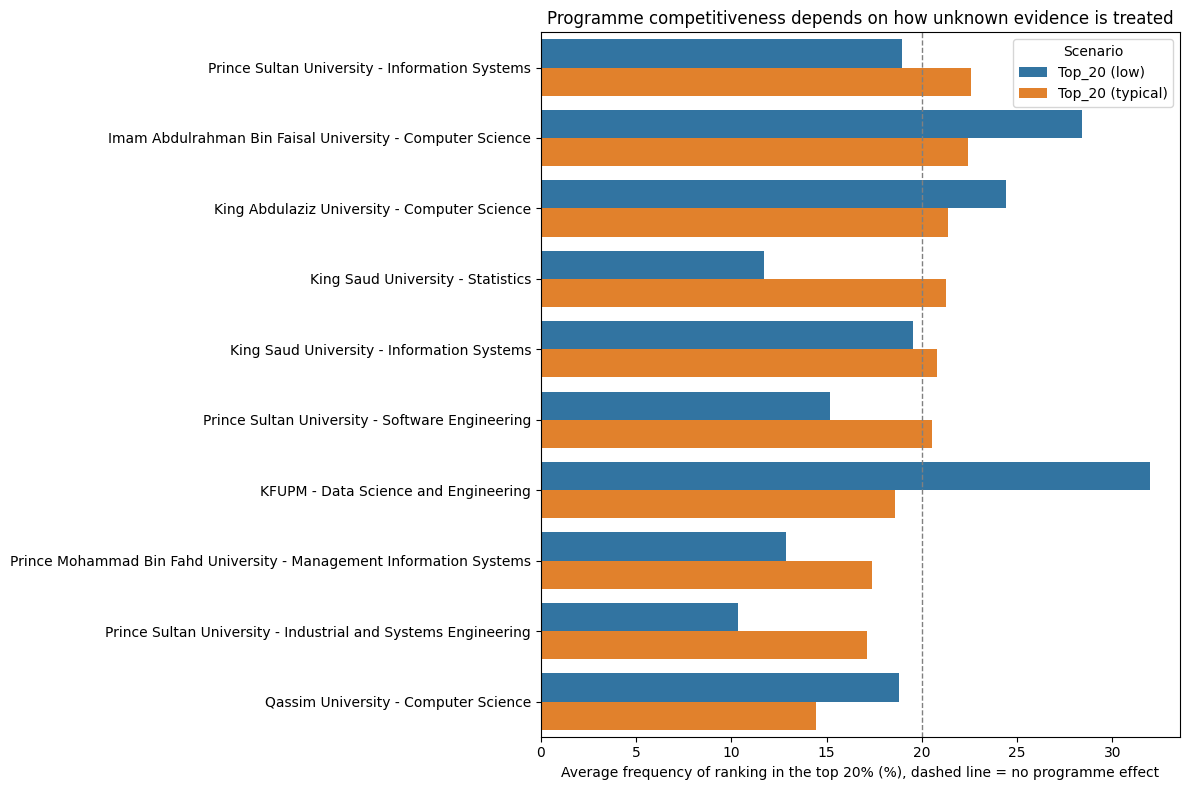

In [12]:
def program_table(r):
    return r.groupby(["University", "Major"]).agg(
        Applicants=("Applicant ID", "count"),
        Mean_rank=("Mean rank", "mean"),
        Top_20=("Top 20% freq", "mean"),
    )

prog = program_table(results["low"]).join(
    program_table(results["typical"])[["Mean_rank", "Top_20"]],
    lsuffix=" (low)", rsuffix=" (typical)",
)
prog["Position (low)"] = prog["Mean_rank (low)"].rank().astype(int)
prog["Position (typical)"] = prog["Mean_rank (typical)"].rank().astype(int)
prog = prog.sort_values("Mean_rank (typical)")
display(prog.round(1))

rho_prog, _ = stats.spearmanr(prog["Mean_rank (low)"], prog["Mean_rank (typical)"])
print(f"Agreement between the two programme orderings (Spearman): {rho_prog:.2f}")

plot = prog.reset_index()
plot["Program"] = plot["University"] + " - " + plot["Major"]
long = plot.melt(id_vars="Program", value_vars=["Top_20 (low)", "Top_20 (typical)"],
                 var_name="Scenario", value_name="Top 20% frequency")
plt.figure(figsize=(12, 8))
sns.barplot(data=long, y="Program", x="Top 20% frequency", hue="Scenario")
plt.axvline(20, color="grey", linestyle="--", linewidth=1)
plt.xlabel("Average frequency of ranking in the top 20% (%), dashed line = no programme effect")
plt.ylabel("")
plt.title("Programme competitiveness depends on how unknown evidence is treated")
plt.tight_layout()
plt.show()

## 5. Predicted vs actual answers (me)

In [13]:
def my_table(mode):
    s = sim[mode]
    t = questions.copy()
    t["Curriculum score"] = my_cur[mode]["Curriculum score"].values
    t["Evidence"] = my_cur[mode]["Evidence"].values
    t["Predicted (curriculum-only)"] = s["me_cur"].mean(axis=0)
    t["Predicted answer"] = s["me_full"].mean(axis=0)
    t["Lower 5%"] = np.percentile(s["me_full"], 5, axis=0)
    t["Upper 95%"] = np.percentile(s["me_full"], 95, axis=0)
    t["Actual answer"] = actual_vec
    t["Difference"] = t["Actual answer"] - t["Predicted answer"]
    return t

def accuracy(t, col):
    a, p = t["Actual answer"].to_numpy(), t[col].to_numpy()
    return {
        "Mean absolute error": np.abs(a - p).mean(),
        "RMSE": np.sqrt(((a - p) ** 2).mean()),
        "Mean signed difference": (a - p).mean(),
        "Spearman correlation": stats.spearmanr(a, p)[0],
        "Questions under-predicted": int((a > p).sum()),
    }

comparison = {m: my_table(m) for m in sim}

acc = pd.DataFrame({
    "Curriculum-only, unknown = low": accuracy(comparison["low"], "Predicted (curriculum-only)"),
    "Like-for-like, unknown = low": accuracy(comparison["low"], "Predicted answer"),
    "Like-for-like, unknown = typical": accuracy(comparison["typical"], "Predicted answer"),
}).T
for m, label in [("low", "Like-for-like, unknown = low"), ("typical", "Like-for-like, unknown = typical")]:
    t = comparison[m]
    acc.loc[label, "90% interval coverage (%)"] = (
        (t["Actual answer"] >= t["Lower 5%"]) & (t["Actual answer"] <= t["Upper 95%"])
    ).mean() * 100
display(acc.round(2))

display(comparison["typical"][[
    "Question ID", "Question", "Curriculum score", "Predicted answer",
    "Lower 5%", "Upper 95%", "Actual answer", "Difference", "Evidence",
]].round(2))

,Mean absolute error,RMSE,Mean signed difference,Spearman correlation,Questions under-predicted,90% interval coverage (%)
"Curriculum-only, unknown = low",3.03,3.28,3.03,0.44,45.0,NaN
"Like-for-like, unknown = low",1.90,2.24,1.84,0.40,41.0,88.89
"Like-for-like, unknown = typical",1.53,1.82,1.47,0.53,41.0,95.56


,Question ID,Question,Curriculum score,Predicted answer,Lower 5%,Upper 95%,Actual answer,Difference,Evidence
0,P01,Python independently,2.0,4.71,2.0,7.0,7.0,2.29,Programming for Analytics
1,P02,Clean modular code,4.0,6.29,4.0,9.0,7.0,0.71,Programming for Analytics
2,P03,Object-oriented programming,3.0,5.48,3.0,8.0,6.0,0.51,Programming for Analytics
3,P04,Debugging and stack traces,4.0,6.28,4.0,9.0,6.0,-0.28,Programming for Analytics
4,P05,Testing and error handling,3.0,5.50,3.0,8.0,7.0,1.50,Programming for Analytics
5,P06,Command line and environments,3.0,5.49,3.0,8.0,8.0,2.51,Programming for Analytics
6,P07,"Git, REST APIs and collaboration",2.0,4.68,2.0,7.0,7.0,2.32,Programming for Analytics
7,D01,Data structures and efficiency,3.0,5.51,3.0,8.0,8.0,2.49,Programming for Analytics
8,D02,SQL filtering and aggregation,6.0,7.86,6.0,10.0,8.0,0.14,Database Management
9,D03,"SQL joins, CTEs and windows",4.0,6.29,4.0,9.0,7.0,0.71,Database Management


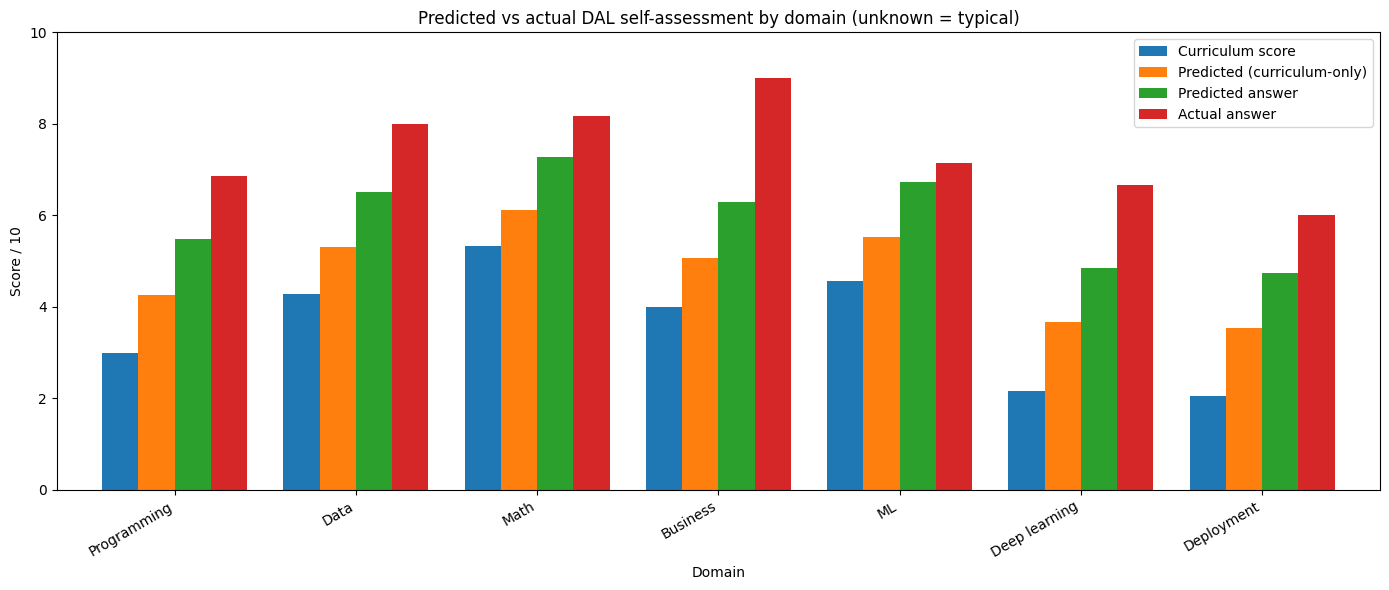

,Curriculum score,Predicted (curriculum-only),Predicted answer,Actual answer
Domain,,,,
Programming,3.00,4.27,5.49,6.86
Data,4.29,5.30,6.51,8.00
Math,5.33,6.12,7.27,8.17
Business,4.00,5.07,6.28,9.00
ML,4.57,5.52,6.73,7.14
Deep learning,2.17,3.67,4.84,6.67
Deployment,2.05,3.54,4.73,6.00


In [14]:
t = comparison["typical"]
dom = t.groupby("Domain", sort=False)[
    ["Curriculum score", "Predicted (curriculum-only)", "Predicted answer", "Actual answer"]
].mean()
dom.plot(kind="bar", figsize=(14, 6), width=0.8)
plt.ylabel("Score / 10")
plt.title("Predicted vs actual DAL self-assessment by domain (unknown = typical)")
plt.ylim(0, 10)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
display(dom.round(2))

## 6. Where would I rank?

The pool is model output, and the model under-predicts my own answers. So I do not report one
number. I use two bounds:

* **Model is right about the pool.** My actual answers against the simulated pool as it is. This is
  the optimistic bound: it assumes real applicants rate themselves as low as the model says.
* **Model under-predicts everyone as much as it under-predicts me.** The pool's scores are lifted by
  my own mean prediction error. This is the pessimistic bound: it assumes nothing about me is
  unusual beyond what the model already knows.

The truth is somewhere in between, and it cannot be narrowed without real DAL responses.


In [15]:
def benchmark(mode):
    s = sim[mode]
    delta = actual_vec.mean() - s["me_full"].mean()
    shifted = 1 + (s["scores"] + delta > s["score_actual"][:, None]).sum(axis=1)
    series = {
        "Predicted, curriculum-only": s["rank_cur"],
        "Predicted, like-for-like": s["rank_full"],
        "Actual vs pool as simulated (optimistic)": s["rank_actual"],
        "Actual vs pool lifted by my error (pessimistic)": shifted,
    }
    tab = pd.DataFrame({
        k: {
            "Mean rank": v.mean(), "Median rank": np.median(v),
            "5th pct": np.percentile(v, 5), "95th pct": np.percentile(v, 95),
            "Top 10% (%)": (v <= 0.10 * N_POP).mean() * 100,
            "Top 20% (%)": (v <= 0.20 * N_POP).mean() * 100,
            "Top 30% (%)": (v <= 0.30 * N_POP).mean() * 100,
        } for k, v in series.items()
    }).T
    return tab, series, delta

bench = {}
for mode in sim:
    tab, series, delta = benchmark(mode)
    bench[mode] = (tab, series)
    print(f"\nUnknown = {mode}  |  my mean answer {actual_vec.mean():.2f}, "
          f"pool mean {sim[mode]['scores'].mean():.2f}, model under-predicts me by {delta:.2f}")
    display(tab.round(1))


Unknown = low  |  my mean answer 7.53, pool mean 5.29, model under-predicts me by 1.84


,Mean rank,Median rank,5th pct,95th pct,Top 10% (%),Top 20% (%),Top 30% (%)
"Predicted, curriculum-only",161.0,169.0,89.0,206.0,0.0,0.3,1.6
"Predicted, like-for-like",90.5,85.0,8.0,192.0,13.5,26.4,38.6
Actual vs pool as simulated (optimistic),9.2,7.0,1.0,24.0,92.9,99.9,100.0
Actual vs pool lifted by my error (pessimistic),85.5,83.0,34.0,144.0,0.5,11.1,31.1



Unknown = typical  |  my mean answer 7.53, pool mean 5.81, model under-predicts me by 1.47


,Mean rank,Median rank,5th pct,95th pct,Top 10% (%),Top 20% (%),Top 30% (%)
"Predicted, curriculum-only",168.1,177.0,101.0,207.0,0.0,0.2,0.9
"Predicted, like-for-like",96.1,93.0,9.0,195.0,12.0,23.9,34.8
Actual vs pool as simulated (optimistic),18.7,15.0,3.0,44.0,64.9,94.2,99.9
Actual vs pool lifted by my error (pessimistic),95.9,95.0,43.0,152.0,0.1,4.9,22.0


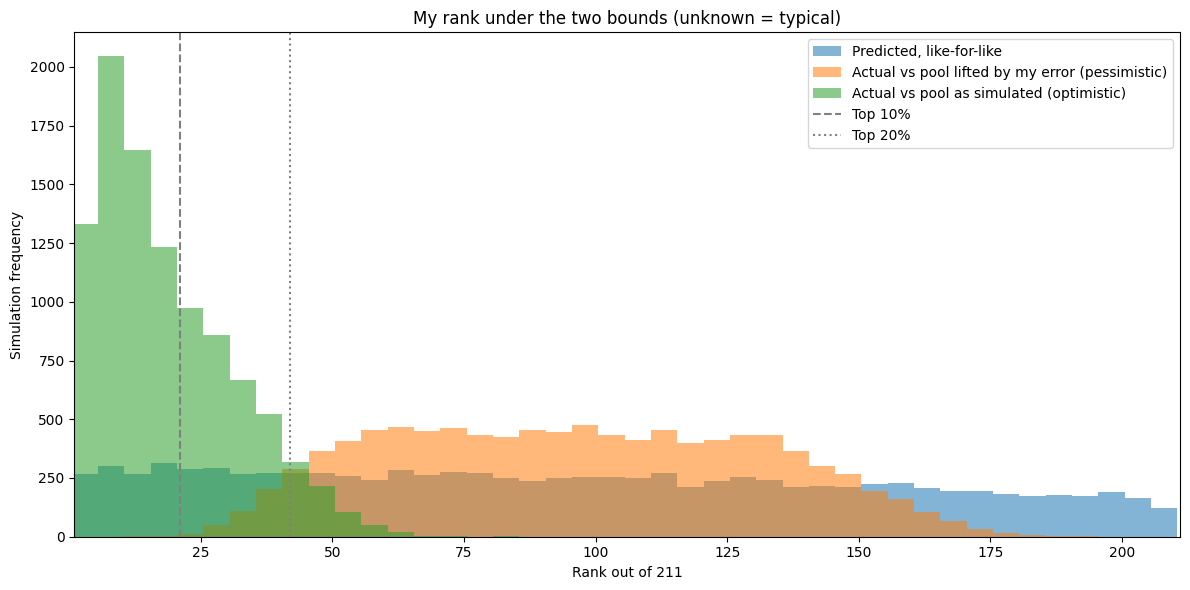

In [16]:
tab, series = bench["typical"]
bins = np.arange(0.5, N_POP + 2.5, 5)
plt.figure(figsize=(12, 6))
for name in ["Predicted, like-for-like",
             "Actual vs pool lifted by my error (pessimistic)",
             "Actual vs pool as simulated (optimistic)"]:
    plt.hist(series[name], bins=bins, alpha=0.55, label=name)
plt.axvline(0.10 * N_POP, color="grey", linestyle="--", label="Top 10%")
plt.axvline(0.20 * N_POP, color="grey", linestyle=":", label="Top 20%")
plt.xlabel(f"Rank out of {N_POP + 1}")
plt.ylabel("Simulation frequency")
plt.title("My rank under the two bounds (unknown = typical)")
plt.xlim(1, N_POP + 1)
plt.legend()
plt.tight_layout()
plt.show()

## 7. What adding KFUPM changed

The previous run had 190 applicants and no KFUPM. This table puts those results next to the
current run. Ranks are also shown as a share of the pool, because the pool size changed.


In [17]:
# Results from the previous run (190 applicants, 9 programmes, no KFUPM)
BEFORE = {
    "low": {"Pool size": 190, "Pool mean score": 5.24, "My mean rank, optimistic": 7.7, "My mean rank, pessimistic": 74.9},
    "typical": {"Pool size": 190, "Pool mean score": 5.81, "My mean rank, optimistic": 16.9, "My mean rank, pessimistic": 87.5},
}

rows = {}
for mode in sim:
    tab = bench[mode][0]
    now = {
        "Pool size": N_POP,
        "Pool mean score": sim[mode]["scores"].mean(),
        "My mean rank, optimistic": tab.loc["Actual vs pool as simulated (optimistic)", "Mean rank"],
        "My mean rank, pessimistic": tab.loc["Actual vs pool lifted by my error (pessimistic)", "Mean rank"],
    }
    for name, before, after in [("Before KFUPM", BEFORE[mode], now)]:
        for key in now:
            rows[(f"unknown = {mode}", key)] = {"Before KFUPM": before[key], "This version": after[key]}
        for key in ["My mean rank, optimistic", "My mean rank, pessimistic"]:
            rows[(f"unknown = {mode}", key.replace("mean rank", "rank as % of pool"))] = {
                "Before KFUPM": before[key] / before["Pool size"] * 100,
                "This version": after[key] / after["Pool size"] * 100,
            }

change = pd.DataFrame(rows).T
change["Change"] = change["This version"] - change["Before KFUPM"]
display(change.round(2))


Before KFUPM  \
unknown = low     Pool size                                190.00   
                  Pool mean score                            5.24   
                  My mean rank, optimistic                   7.70   
                  My mean rank, pessimistic                 74.90   
                  My rank as % of pool, optimistic           4.05   
                  My rank as % of pool, pessimistic         39.42   
unknown = typical Pool size                                190.00   
                  Pool mean score                            5.81   
                  My mean rank, optimistic                  16.90   
                  My mean rank, pessimistic                 87.50   
                  My rank as % of pool, optimistic           8.89   
                  My rank as % of pool, pessimistic         46.05   

                                                     This version  Change  
unknown = low     Pool size                                210.00   20.00  
                  Pool mean score                            5.29    0.05  
                  My mean rank, optimistic                   9.19    1.49  
                  My mean rank, pessimistic                 85.46   10.56  
                  My rank as % of pool, optimistic           4.38    0.32  
                  My rank as % of pool, pessimistic         40.69    1.27  
unknown = typical Pool size                                210.00   20.00  
                  Pool mean score                            5.81   -0.00  
                  My mean rank, optimistic                  18.69    1.79  
                  My mean rank, pessimistic                 95.92    8.42  
                  My rank as % of pool, optimistic           8.90    0.01  
                  My rank as % of pool, pessimistic         45.67   -0.38

## What this can and cannot say

* The applicants are fictional and the scores describe curriculum exposure, not skill. Nothing here
  estimates a real DAL acceptance chance.
* Reporting bias, the GPA and experience effects, and the size of person-level variation are
  assumptions. They were chosen, not estimated.
* The only real data point is one person's self-assessment. It is enough to show the model is
  under-predicting, not enough to recalibrate it.
* To turn this into a real benchmark it needs actual DAL responses, even a few dozen, to fit the
  assumed parameters against.